# Lab 3B: MFCC and Chroma Feature Extraction

Extract Mel-Frequency Cepstral Coefficients (MFCCs) and Chroma features from audio signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Audio File

In [3]:
# Load audio file
audio_path = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3"  # CHANGE THIS

y, sr = librosa.load(audio_path, sr=None)

print(f"Audio loaded: {audio_path}")
print(f"Sample rate: {sr} Hz")
print(f"Duration: {len(y)/sr:.2f} seconds")
print(f"Shape: {y.shape}")

Audio loaded: /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3
Sample rate: 44100 Hz
Duration: 4.76 seconds
Shape: (209761,)


## 2. Extract MFCCs

MFCCs capture the spectral envelope of audio, commonly used in speech recognition.

In [4]:
# Extract MFCCs
n_mfcc = 13  # Standard number of coefficients
n_fft = 2048
hop_length = 512

mfcc = librosa.feature.mfcc(
    y=y, 
    sr=sr, 
    n_mfcc=n_mfcc,
    n_fft=n_fft,
    hop_length=hop_length
)

print(f"MFCC shape: {mfcc.shape}")
print(f"Number of coefficients: {mfcc.shape[0]}")
print(f"Number of frames: {mfcc.shape[1]}")

MFCC shape: (13, 410)
Number of coefficients: 13
Number of frames: 410


## 3. Extract Delta and Delta-Delta MFCCs

Delta features capture temporal dynamics of MFCCs.

In [5]:
# Compute delta features (first derivative)
mfcc_delta = librosa.feature.delta(mfcc)

# Compute delta-delta features (second derivative)
mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

print(f"Delta MFCC shape: {mfcc_delta.shape}")
print(f"Delta-Delta MFCC shape: {mfcc_delta2.shape}")

# Combined feature vector: 13 + 13 + 13 = 39 features per frame
mfcc_combined = np.vstack([mfcc, mfcc_delta, mfcc_delta2])
print(f"\nCombined MFCC features shape: {mfcc_combined.shape}")
print(f"Total features per frame: {mfcc_combined.shape[0]}")

Delta MFCC shape: (13, 410)
Delta-Delta MFCC shape: (13, 410)

Combined MFCC features shape: (39, 410)
Total features per frame: 39


## 4. Visualize MFCCs

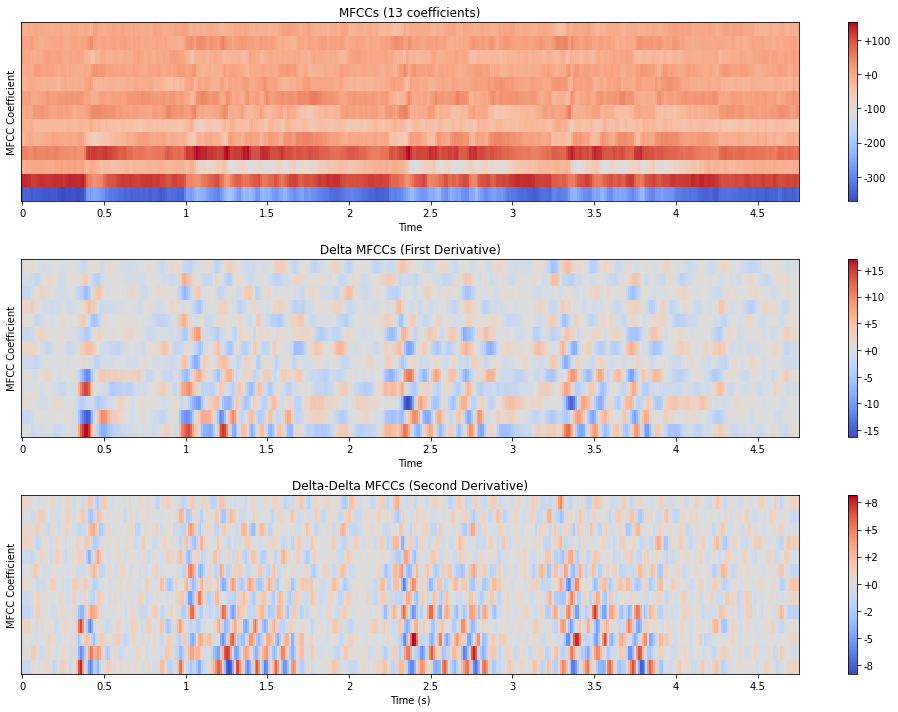

Saved: mfcc_visualization.png


In [8]:
# Create time axis
frames = range(mfcc.shape[1])
time_frames = librosa.frames_to_time(frames, sr=sr, hop_length=hop_length)

# Plot MFCCs
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# MFCC
img1 = librosa.display.specshow(mfcc, x_axis='time', sr=sr, hop_length=hop_length,
                                ax=axes[0], cmap='coolwarm')
axes[0].set_ylabel('MFCC Coefficient')
axes[0].set_title('MFCCs (13 coefficients)')
plt.colorbar(img1, ax=axes[0], format='%+2.0f')

# Delta MFCC
img2 = librosa.display.specshow(mfcc_delta, x_axis='time', sr=sr, hop_length=hop_length,
                                ax=axes[1], cmap='coolwarm')
axes[1].set_ylabel('MFCC Coefficient')
axes[1].set_title('Delta MFCCs (First Derivative)')
plt.colorbar(img2, ax=axes[1], format='%+2.0f')

# Delta-Delta MFCC
img3 = librosa.display.specshow(mfcc_delta2, x_axis='time', sr=sr, hop_length=hop_length,
                                ax=axes[2], cmap='coolwarm')
axes[2].set_ylabel('MFCC Coefficient')
axes[2].set_xlabel('Time (s)')
axes[2].set_title('Delta-Delta MFCCs (Second Derivative)')
plt.colorbar(img3, ax=axes[2], format='%+2.0f')

plt.tight_layout()
plt.savefig('results/mfcc_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: mfcc_visualization.png")

## 5. MFCC Statistics

In [7]:
# Calculate statistics for each MFCC coefficient
mfcc_mean = np.mean(mfcc, axis=1)
mfcc_std = np.std(mfcc, axis=1)
mfcc_min = np.min(mfcc, axis=1)
mfcc_max = np.max(mfcc, axis=1)

print("MFCC Statistics (aggregated over time):")
print("="*60)
print(f"{'Coeff':<8} {'Mean':<12} {'Std':<12} {'Min':<12} {'Max':<12}")
print("="*60)
for i in range(n_mfcc):
    print(f"MFCC-{i:<2} {mfcc_mean[i]:>10.4f}  {mfcc_std[i]:>10.4f}  "
          f"{mfcc_min[i]:>10.4f}  {mfcc_max[i]:>10.4f}")
print("="*60)

MFCC Statistics (aggregated over time):
Coeff    Mean         Std          Min          Max         
MFCC-0   -300.0369     40.7279   -370.2344   -196.4710
MFCC-1     98.3532     25.6761     16.8362    136.6494
MFCC-2    -49.5093     36.9896   -125.9217     13.7703
MFCC-3     86.7286     27.0841     27.0286    150.8706
MFCC-4      1.6287     23.2819    -70.0293     50.3898
MFCC-5    -34.2419     11.3015    -73.3074     -0.6594
MFCC-6      0.2378     21.8446    -52.2775     54.9197
MFCC-7     15.8070     14.3052    -29.5718     57.3472
MFCC-8     -1.3417     13.3215    -36.4649     31.7869
MFCC-9      4.1296      9.9392    -21.4507     39.3650
MFCC-10    -7.5075     12.2484    -45.3788     16.0727
MFCC-11     9.2238     11.4452    -15.1613     50.0768
MFCC-12    -3.4365      9.1310    -39.9856     16.1005


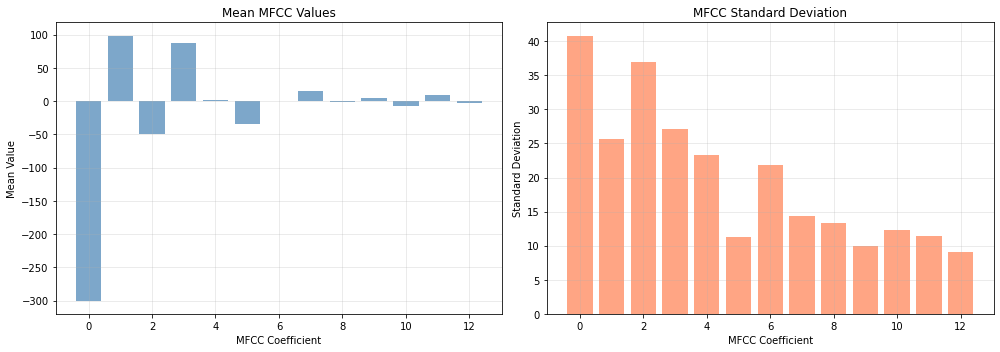

Saved: mfcc_statistics.png


In [9]:
# Plot MFCC statistics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

coeffs = range(n_mfcc)

# Mean values
axes[0].bar(coeffs, mfcc_mean, color='steelblue', alpha=0.7)
axes[0].set_xlabel('MFCC Coefficient')
axes[0].set_ylabel('Mean Value')
axes[0].set_title('Mean MFCC Values')
axes[0].grid(True, alpha=0.3)

# Standard deviation
axes[1].bar(coeffs, mfcc_std, color='coral', alpha=0.7)
axes[1].set_xlabel('MFCC Coefficient')
axes[1].set_ylabel('Standard Deviation')
axes[1].set_title('MFCC Standard Deviation')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/mfcc_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: mfcc_statistics.png")

## 6. Extract Chroma Features

Chroma features represent the 12 pitch classes (C, C#, D, ..., B), useful for music analysis.

In [10]:
# Extract chroma features
chroma = librosa.feature.chroma_stft(
    y=y, 
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)

print(f"Chroma shape: {chroma.shape}")
print(f"Number of pitch classes: {chroma.shape[0]}")
print(f"Number of frames: {chroma.shape[1]}")

# Pitch class names
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
print(f"\nPitch classes: {', '.join(pitch_classes)}")

Chroma shape: (12, 410)
Number of pitch classes: 12
Number of frames: 410

Pitch classes: C, C#, D, D#, E, F, F#, G, G#, A, A#, B


## 7. Visualize Chroma Features

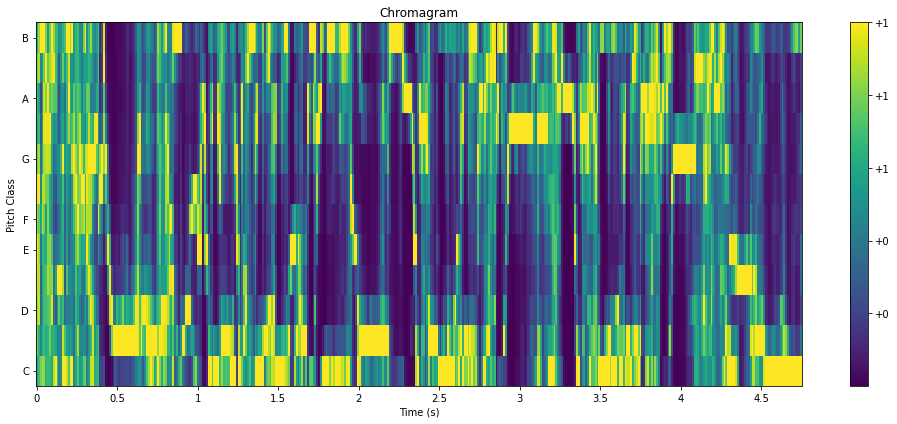

Saved: chroma_visualization.png


In [11]:
# Plot chroma features
plt.figure(figsize=(14, 6))

librosa.display.specshow(
    chroma, 
    x_axis='time', 
    y_axis='chroma',
    sr=sr, 
    hop_length=hop_length,
    cmap='viridis'
)

plt.colorbar(format='%+2.0f')
plt.ylabel('Pitch Class')
plt.xlabel('Time (s)')
plt.title('Chromagram')
plt.tight_layout()
plt.savefig('results/chroma_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: chroma_visualization.png")

## 8. Chroma Statistics

In [12]:
# Calculate statistics for each pitch class
chroma_mean = np.mean(chroma, axis=1)
chroma_std = np.std(chroma, axis=1)
chroma_max = np.max(chroma, axis=1)

print("Chroma Statistics (aggregated over time):")
print("="*60)
print(f"{'Pitch':<8} {'Mean':<15} {'Std':<15} {'Max':<15}")
print("="*60)
for i, pitch in enumerate(pitch_classes):
    print(f"{pitch:<8} {chroma_mean[i]:>13.4f}  {chroma_std[i]:>13.4f}  {chroma_max[i]:>13.4f}")
print("="*60)

# Find dominant pitch class
dominant_pitch_idx = np.argmax(chroma_mean)
print(f"\nDominant pitch class: {pitch_classes[dominant_pitch_idx]}")

Chroma Statistics (aggregated over time):
Pitch    Mean            Std             Max            
C               0.5964         0.3382         1.0000
C#              0.5440         0.3363         1.0000
D               0.3721         0.2852         1.0000
D#              0.2953         0.2715         1.0000
E               0.2990         0.2748         1.0000
F               0.2789         0.2491         1.0000
F#              0.3094         0.2659         1.0000
G               0.3931         0.3124         1.0000
G#              0.4515         0.3227         1.0000
A               0.4432         0.3050         1.0000
A#              0.3882         0.2884         1.0000
B               0.5009         0.3134         1.0000

Dominant pitch class: C


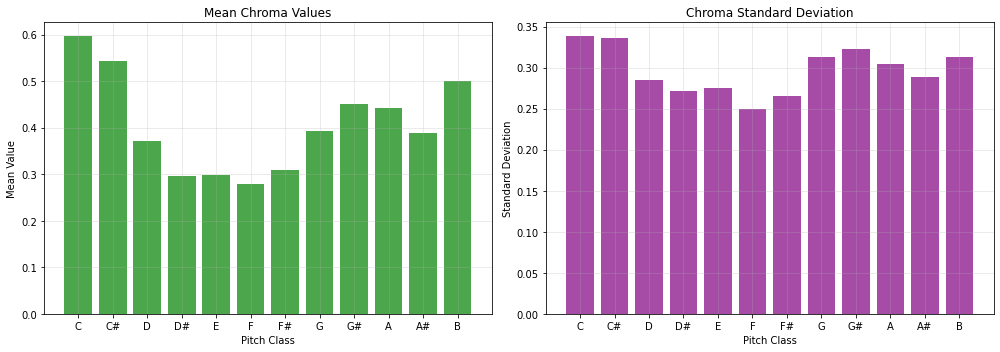

Saved: chroma_statistics.png


In [14]:
# Plot chroma statistics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Mean values
axes[0].bar(pitch_classes, chroma_mean, color='green', alpha=0.7)
axes[0].set_xlabel('Pitch Class')
axes[0].set_ylabel('Mean Value')
axes[0].set_title('Mean Chroma Values')
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='x', rotation=0)

# Standard deviation
axes[1].bar(pitch_classes, chroma_std, color='purple', alpha=0.7)
axes[1].set_xlabel('Pitch Class')
axes[1].set_ylabel('Standard Deviation')
axes[1].set_title('Chroma Standard Deviation')
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('results/chroma_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: chroma_statistics.png")

## 9. Create Feature Summary DataFrame

In [15]:
# MFCC summary
mfcc_df = pd.DataFrame({
    'Coefficient': [f'MFCC-{i}' for i in range(n_mfcc)],
    'Mean': mfcc_mean,
    'Std': mfcc_std,
    'Min': mfcc_min,
    'Max': mfcc_max
})

print("MFCC Summary DataFrame:")
print(mfcc_df)
print()

# Chroma summary
chroma_df = pd.DataFrame({
    'Pitch_Class': pitch_classes,
    'Mean': chroma_mean,
    'Std': chroma_std,
    'Max': chroma_max
})

print("Chroma Summary DataFrame:")
print(chroma_df)

MFCC Summary DataFrame:
   Coefficient        Mean        Std         Min         Max
0       MFCC-0 -300.036926  40.727886 -370.234406 -196.471024
1       MFCC-1   98.353180  25.676064   16.836246  136.649445
2       MFCC-2  -49.509281  36.989574 -125.921700   13.770321
3       MFCC-3   86.728638  27.084127   27.028587  150.870605
4       MFCC-4    1.628712  23.281885  -70.029266   50.389778
5       MFCC-5  -34.241905  11.301533  -73.307449   -0.659378
6       MFCC-6    0.237783  21.844614  -52.277512   54.919716
7       MFCC-7   15.806984  14.305159  -29.571819   57.347179
8       MFCC-8   -1.341654  13.321541  -36.464912   31.786880
9       MFCC-9    4.129601   9.939187  -21.450668   39.364975
10     MFCC-10   -7.507530  12.248400  -45.378799   16.072666
11     MFCC-11    9.223772  11.445241  -15.161280   50.076836
12     MFCC-12   -3.436459   9.130974  -39.985619   16.100540

Chroma Summary DataFrame:
   Pitch_Class      Mean       Std  Max
0            C  0.596447  0.338203  1.0
1

## 10. Save Features to CSV

In [17]:
# Save MFCC summary
mfcc_df.to_csv('results/mfcc_summary.csv', index=False)
print("Saved: mfcc_summary.csv")

# Save Chroma summary
chroma_df.to_csv('results/chroma_summary.csv', index=False)
print("Saved: chroma_summary.csv")

# Save full MFCC features (all frames)
mfcc_full_df = pd.DataFrame(
    mfcc.T,
    columns=[f'MFCC-{i}' for i in range(n_mfcc)]
)
mfcc_full_df['Time'] = time_frames
mfcc_full_df = mfcc_full_df[['Time'] + [f'MFCC-{i}' for i in range(n_mfcc)]]
mfcc_full_df.to_csv('results/mfcc_full.csv', index=False)
print("Saved: mfcc_full.csv")

# Save full Chroma features (all frames)
chroma_full_df = pd.DataFrame(
    chroma.T,
    columns=pitch_classes
)
chroma_full_df['Time'] = time_frames
chroma_full_df = chroma_full_df[['Time'] + pitch_classes]
chroma_full_df.to_csv('results/chroma_full.csv', index=False)
print("Saved: chroma_full.csv")

Saved: mfcc_summary.csv
Saved: chroma_summary.csv
Saved: mfcc_full.csv
Saved: chroma_full.csv


## 11. Combined Feature Visualization

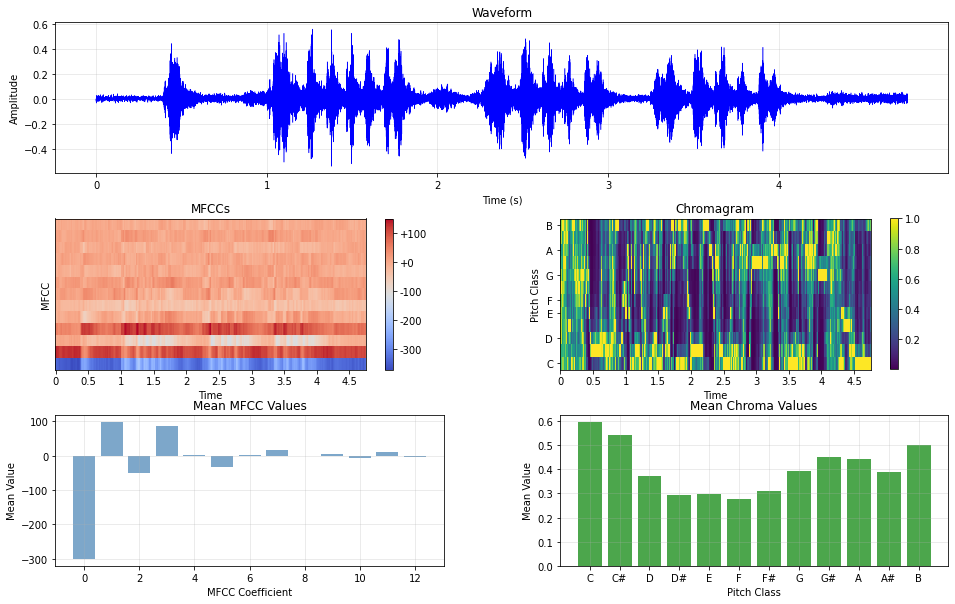

Saved: combined_features.png


In [18]:
# Create comprehensive visualization
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Waveform
ax1 = fig.add_subplot(gs[0, :])
time = np.linspace(0, len(y)/sr, len(y))
ax1.plot(time, y, linewidth=0.5, color='blue')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.set_title('Waveform')
ax1.grid(True, alpha=0.3)

# MFCC
ax2 = fig.add_subplot(gs[1, 0])
img1 = librosa.display.specshow(mfcc, x_axis='time', sr=sr, hop_length=hop_length,
                                ax=ax2, cmap='coolwarm')
ax2.set_ylabel('MFCC')
ax2.set_title('MFCCs')
plt.colorbar(img1, ax=ax2, format='%+2.0f')

# Chroma
ax3 = fig.add_subplot(gs[1, 1])
img2 = librosa.display.specshow(chroma, x_axis='time', y_axis='chroma', sr=sr,
                                hop_length=hop_length, ax=ax3, cmap='viridis')
ax3.set_ylabel('Pitch Class')
ax3.set_title('Chromagram')
plt.colorbar(img2, ax=ax3)

# MFCC Statistics
ax4 = fig.add_subplot(gs[2, 0])
ax4.bar(range(n_mfcc), mfcc_mean, color='steelblue', alpha=0.7)
ax4.set_xlabel('MFCC Coefficient')
ax4.set_ylabel('Mean Value')
ax4.set_title('Mean MFCC Values')
ax4.grid(True, alpha=0.3)

# Chroma Statistics
ax5 = fig.add_subplot(gs[2, 1])
ax5.bar(pitch_classes, chroma_mean, color='green', alpha=0.7)
ax5.set_xlabel('Pitch Class')
ax5.set_ylabel('Mean Value')
ax5.set_title('Mean Chroma Values')
ax5.grid(True, alpha=0.3)

plt.savefig('results/combined_features.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: combined_features.png")

## 12. Feature Vector for Machine Learning

In [19]:
# Create aggregated feature vector for ML
# This creates a single feature vector per audio file

feature_vector = np.concatenate([
    mfcc_mean,           # 13 features
    mfcc_std,            # 13 features
    chroma_mean,         # 12 features
    chroma_std           # 12 features
])

print(f"Feature vector shape: {feature_vector.shape}")
print(f"Total features: {len(feature_vector)}")
print(f"\nFeature breakdown:")
print(f"  MFCC mean: 13")
print(f"  MFCC std: 13")
print(f"  Chroma mean: 12")
print(f"  Chroma std: 12")
print(f"  Total: 50 features")

# Create feature names
feature_names = (
    [f'mfcc_mean_{i}' for i in range(n_mfcc)] +
    [f'mfcc_std_{i}' for i in range(n_mfcc)] +
    [f'chroma_mean_{p}' for p in pitch_classes] +
    [f'chroma_std_{p}' for p in pitch_classes]
)

# Create DataFrame
feature_df = pd.DataFrame([feature_vector], columns=feature_names)
print("\nFeature Vector DataFrame:")
print(feature_df.T)  # Transpose for better viewing

Feature vector shape: (50,)
Total features: 50

Feature breakdown:
  MFCC mean: 13
  MFCC std: 13
  Chroma mean: 12
  Chroma std: 12
  Total: 50 features

Feature Vector DataFrame:
                         0
mfcc_mean_0    -300.036926
mfcc_mean_1      98.353180
mfcc_mean_2     -49.509281
mfcc_mean_3      86.728638
mfcc_mean_4       1.628712
mfcc_mean_5     -34.241905
mfcc_mean_6       0.237783
mfcc_mean_7      15.806984
mfcc_mean_8      -1.341654
mfcc_mean_9       4.129601
mfcc_mean_10     -7.507530
mfcc_mean_11      9.223772
mfcc_mean_12     -3.436459
mfcc_std_0       40.727886
mfcc_std_1       25.676064
mfcc_std_2       36.989574
mfcc_std_3       27.084127
mfcc_std_4       23.281885
mfcc_std_5       11.301533
mfcc_std_6       21.844614
mfcc_std_7       14.305159
mfcc_std_8       13.321541
mfcc_std_9        9.939187
mfcc_std_10      12.248400
mfcc_std_11      11.445241
mfcc_std_12       9.130974
chroma_mean_C     0.596447
chroma_mean_C#    0.544004
chroma_mean_D     0.372064
chroma_me

In [20]:
# Save feature vector
feature_df.to_csv('results/feature_vector.csv', index=False)
print("Saved: feature_vector.csv")

# Also save as numpy array
np.save('results/feature_vector.npy', feature_vector)
print("Saved: feature_vector.npy")

Saved: feature_vector.csv
Saved: feature_vector.npy


## Summary

This notebook extracted:

**MFCC Features:**
- 13 MFCC coefficients
- Delta MFCCs (first derivative)
- Delta-Delta MFCCs (second derivative)
- Total: 39 features per frame

**Chroma Features:**
- 12 pitch class features
- Representing musical pitch content

**Output Files:**
- `mfcc_visualization.png` - MFCC, delta, delta-delta heatmaps
- `mfcc_statistics.png` - MFCC statistical plots
- `chroma_visualization.png` - Chromagram
- `chroma_statistics.png` - Chroma statistical plots
- `combined_features.png` - Comprehensive visualization
- `mfcc_summary.csv` - MFCC statistics
- `chroma_summary.csv` - Chroma statistics
- `mfcc_full.csv` - All MFCC frames
- `chroma_full.csv` - All chroma frames
- `feature_vector.csv` - Aggregated ML feature vector (50 features)
- `feature_vector.npy` - Numpy format

**Applications:**
- MFCCs: Speech recognition, speaker identification, audio classification
- Chroma: Music analysis, chord recognition, key detection